### POC ML for Futures Trading


In [1]:
# Load API key from .env file
from dotenv import load_dotenv
import os

load_dotenv()  # Load environment variables from .env file
api_key = os.environ.get('POLYGON_API_KEY')

if api_key:
    print(f"API key loaded successfully (length: {len(api_key)} chars)")
else:
    print("POLYGON_API_KEY not found in .env file!")
    print("Create a .env file in the trading_brains folder with:")
    print("POLYGON_API_KEY=your-api-key-here")

API key loaded successfully (length: 32 chars)


In [35]:
# =============================================================================
# Data Import from Polygon.io (Massive) - 1-Minute Stock Data
# =============================================================================
import requests
import pandas as pd
from datetime import datetime, timedelta
import time

# Load API key from environment

def fetch_polygon_1min_data(symbol: str, start_date: str, end_date: str, api_key: str) -> pd.DataFrame:
    """
    Fetch 1-minute OHLCV data from Polygon.io
    
    Args:
        symbol: Stock ticker symbol (e.g., 'SPY', 'QQQ', 'IWM')
        start_date: Start date in 'YYYY-MM-DD' format
        end_date: End date in 'YYYY-MM-DD' format
        api_key: Polygon.io API key
    
    Returns:
        DataFrame with columns: timestamp, open, high, low, close, volume, vwap
    """
    all_data = []
    multiplier = 1
    timespan = "minute"
    
    url = f"https://api.polygon.io/v2/aggs/ticker/{symbol}/range/{multiplier}/{timespan}/{start_date}/{end_date}"
    
    params = {
        "adjusted": "true",
        "sort": "asc",
        "limit": 50000,
        "apiKey": api_key
    }
    
    print(f"Fetching {symbol} data from {start_date} to {end_date}...")
    
    while url:
        response = requests.get(url, params=params)
        
        if response.status_code != 200:
            print(f"❌ Error: {response.status_code} - {response.text}")
            break
            
        data = response.json()
        
        if data.get("results"):
            all_data.extend(data["results"])
            print(f"  Fetched {len(data['results'])} bars (total: {len(all_data)})")
        
        # Handle pagination
        url = data.get("next_url")
        if url:
            params = {"apiKey": api_key}
            time.sleep(0.15)  # Rate limiting
    
    if not all_data:
        print("❌ No data received")
        return pd.DataFrame()
    
    # Convert to DataFrame
    df = pd.DataFrame(all_data)
    
    # Rename columns to standard format
    df = df.rename(columns={
        "t": "timestamp",
        "o": "open",
        "h": "high",
        "l": "low",
        "c": "close",
        "v": "volume",
        "vw": "vwap",
        "n": "num_trades"
    })
    
    # Convert timestamp from milliseconds to datetime
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df = df.set_index("timestamp")
    
    # Select relevant columns
    cols = ["open", "high", "low", "close", "volume"]
    if "vwap" in df.columns:
        cols.append("vwap")
    
    df = df[cols]
    
    print(f"✅ Loaded {len(df)} 1-minute bars for {symbol}")
    print(f"   Date range: {df.index.min()} to {df.index.max()}")
    
    return df

# Example: Fetch SPY (S&P 500 ETF) as a proxy for index
# Polygon free tier: 2 years of historical data
# Adjust dates as needed
end_date = datetime.now().strftime("%Y-%m-%d")
start_date = (datetime.now() - timedelta(days=620)).strftime("%Y-%m-%d")  # Last 2 years

# Uncomment to fetch data:
df = fetch_polygon_1min_data("SPY", start_date, end_date, api_key)

Fetching SPY data from 2024-06-30 to 2026-03-12...
❌ Error: 429 - {"status":"ERROR","request_id":"f6057307efc91a91313d2f09d967bca7","error":"You've exceeded the maximum requests per minute, please wait or upgrade your subscription to continue. https://massive.com/pricing"}
❌ No data received


In [5]:
df.head()

,open,high,low,close,volume,vwap
timestamp,,,,,,
2025-02-05 09:00:00,598.43,598.43,598.43,598.43,655.0,598.5489
2025-02-05 09:01:00,598.36,598.51,598.34,598.51,1591.0,598.4282
2025-02-05 09:02:00,598.60,598.60,598.54,598.60,827.0,598.5805
2025-02-05 09:03:00,598.67,598.67,598.57,598.57,504.0,598.6404
2025-02-05 09:06:00,598.98,599.03,598.98,599.03,427.0,598.9988


# Feature Engineering

- Creation of common metrics for time-series
- RSI, MACD, Bollinger Mavg, ATR, Stochastic-K, Return 1, Return 5, Rolling Average 30, 60, 90, 120, Volatility

In [6]:
# =============================================================================
# Data Preparation - Standardize column names and validate data
# =============================================================================

# Standardize column names to capitalized format (Open, High, Low, Close, Volume)
df.columns = df.columns.str.capitalize()

# Display data info
print("=" * 60)
print("DATA SUMMARY")
print("=" * 60)
print(f"\n📊 DataFrame shape: {df.shape}")
print(f"📅 Date range: {df.index.min()} to {df.index.max()}")
print(f"🕐 Frequency: 1-minute bars")
print(f"\n📋 Columns: {list(df.columns)}")
print(f"\n🔍 Missing values per column:")
print(df.isnull().sum())



DATA SUMMARY

📊 DataFrame shape: (236858, 6)
📅 Date range: 2025-02-05 09:00:00 to 2026-03-11 23:59:00
🕐 Frequency: 1-minute bars

📋 Columns: ['Open', 'High', 'Low', 'Close', 'Volume', 'Vwap']

🔍 Missing values per column:
Open      0
High      0
Low       0
Close     0
Volume    0
Vwap      0
dtype: int64


In [7]:
df.head(20)

,Open,High,Low,Close,Volume,Vwap
timestamp,,,,,,
2025-02-05 09:00:00,598.43,598.43,598.43,598.43,655.0,598.5489
2025-02-05 09:01:00,598.36,598.51,598.34,598.51,1591.0,598.4282
2025-02-05 09:02:00,598.60,598.60,598.54,598.60,827.0,598.5805
2025-02-05 09:03:00,598.67,598.67,598.57,598.57,504.0,598.6404
2025-02-05 09:06:00,598.98,599.03,598.98,599.03,427.0,598.9988
2025-02-05 09:07:00,598.99,598.99,598.99,598.99,429.0,598.9646
2025-02-05 09:08:00,598.94,598.94,598.94,598.94,594.0,598.9551
2025-02-05 09:09:00,598.82,598.87,598.78,598.78,8754.0,598.8246
2025-02-05 09:10:00,598.99,598.99,598.99,598.99,628.0,598.8850


In [8]:
# =============================================================================
# FEATURE ENGINEERING - Technical Indicators for 1-Minute Data
# =============================================================================
import numpy as np

def calculate_rsi(prices: pd.Series, period: int = 14) -> pd.Series:
    """Calculate Relative Strength Index"""
    delta = prices.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calculate_macd(prices: pd.Series, fast: int = 12, slow: int = 26, signal: int = 9):
    """Calculate MACD, Signal line, and Histogram"""
    ema_fast = prices.ewm(span=fast, adjust=False).mean()
    ema_slow = prices.ewm(span=slow, adjust=False).mean()
    macd = ema_fast - ema_slow
    macd_signal = macd.ewm(span=signal, adjust=False).mean()
    macd_hist = macd - macd_signal
    return macd, macd_signal, macd_hist

def calculate_bollinger_bands(prices: pd.Series, period: int = 20, std_dev: float = 2.0):
    """Calculate Bollinger Bands"""
    middle = prices.rolling(window=period).mean()
    std = prices.rolling(window=period).std()
    upper = middle + (std * std_dev)
    lower = middle - (std * std_dev)
    return middle, upper, lower

def calculate_atr(high: pd.Series, low: pd.Series, close: pd.Series, period: int = 14) -> pd.Series:
    """Calculate Average True Range"""
    tr1 = high - low
    tr2 = abs(high - close.shift())
    tr3 = abs(low - close.shift())
    tr = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    return tr.rolling(window=period).mean()

def calculate_stochastic(high: pd.Series, low: pd.Series, close: pd.Series, period: int = 14) -> pd.Series:
    """Calculate Stochastic Oscillator %K"""
    lowest_low = low.rolling(window=period).min()
    highest_high = high.rolling(window=period).max()
    return 100 * (close - lowest_low) / (highest_high - lowest_low)

# Apply feature engineering to df
print("=" * 60)
print("FEATURE ENGINEERING")
print("=" * 60)

# OHLC Standard Deviation (intraday volatility measure)
df['OHLC_Std'] = df[['Open', 'High', 'Low', 'Close']].std(axis=1)

# RSI
df['RSI'] = calculate_rsi(df['Close'], period=14)

# MACD
df['MACD'], df['MACD_Signal'], df['MACD_Hist'] = calculate_macd(df['Close'])

# Bollinger Bands
df['BB_Middle'], df['BB_Upper'], df['BB_Lower'] = calculate_bollinger_bands(df['Close'], period=20)

# ATR (Average True Range)
df['ATR'] = calculate_atr(df['High'], df['Low'], df['Close'], period=14)

# Stochastic Oscillator
df['Stochastic_K'] = calculate_stochastic(df['High'], df['Low'], df['Close'], period=14)

# Returns (1-bar and 5-bar)
df['Return_1'] = df['Close'].pct_change(1)
df['Return_5'] = df['Close'].pct_change(5)

# Simple Moving Averages (adjusted for 1-minute data)
df['SMA_30'] = df['Close'].rolling(window=30).mean()    # 30-minute SMA
df['SMA_60'] = df['Close'].rolling(window=60).mean()    # 1-hour SMA
df['SMA_120'] = df['Close'].rolling(window=120).mean()  # 2-hour SMA
df['SMA_390'] = df['Close'].rolling(window=390).mean()  # ~1 trading day SMA

# Volatility (20-bar rolling std of returns)
df['Volatility_20'] = df['Return_1'].rolling(window=20).std()

# Volume-based features
df['Volume_SMA_20'] = df['Volume'].rolling(window=20).mean()
df['Volume_Ratio'] = df['Volume'] / df['Volume_SMA_20']

# Price position within day's range
df['Price_Position'] = (df['Close'] - df['Low']) / (df['High'] - df['Low'] + 1e-10)

print("\n✅ Feature engineering complete!")
print(f"\n📊 DataFrame shape: {df.shape}")
print(f"\n📋 New columns added:")
new_cols = [col for col in df.columns if col not in ['Open', 'High', 'Low', 'Close', 'Volume', 'Vwap']]
for col in new_cols:
    print(f"  - {col}")

print(f"\n🔍 Missing values (from rolling calculations):")
print(df.isnull().sum().tail(10))

FEATURE ENGINEERING

✅ Feature engineering complete!

📊 DataFrame shape: (236858, 26)

📋 New columns added:
  - OHLC_Std
  - RSI
  - MACD
  - MACD_Signal
  - MACD_Hist
  - BB_Middle
  - BB_Upper
  - BB_Lower
  - ATR
  - Stochastic_K
  - Return_1
  - Return_5
  - SMA_30
  - SMA_60
  - SMA_120
  - SMA_390
  - Volatility_20
  - Volume_SMA_20
  - Volume_Ratio
  - Price_Position

🔍 Missing values (from rolling calculations):
Return_1            1
Return_5            5
SMA_30             29
SMA_60             59
SMA_120           119
SMA_390           389
Volatility_20      20
Volume_SMA_20      19
Volume_Ratio       19
Price_Position      0
dtype: int64


In [9]:
# =============================================================================
# LAGGED FEATURES - Capture temporal dependencies
# =============================================================================

print("=" * 60)
print("CREATING LAGGED FEATURES")
print("=" * 60)

# Define lag periods (in minutes for 1-min data)
lag_periods = [1, 5, 15, 30, 60]  # 1min, 5min, 15min, 30min, 1hour

# Store original column count
original_cols = len(df.columns)

# ===== Price Lags =====
print("\n📊 Adding price lags...")
for lag in lag_periods:
    df[f'Close_lag_{lag}'] = df['Close'].shift(lag)
    df[f'Open_lag_{lag}'] = df['Open'].shift(lag)

# ===== Return Lags =====
print("📈 Adding return lags...")
df['Return'] = df['Close'].pct_change()
for lag in lag_periods:
    df[f'Return_lag_{lag}'] = df['Return'].shift(lag)

# ===== Volatility Lags (rolling std of returns) =====
print("📉 Adding volatility lags...")
df['Volatility_5'] = df['Return'].rolling(window=5).std()
df['Volatility_15'] = df['Return'].rolling(window=15).std()
df['Volatility_30'] = df['Return'].rolling(window=30).std()

for lag in [1, 5, 15]:
    df[f'Volatility_5_lag_{lag}'] = df['Volatility_5'].shift(lag)

# ===== Volume Lags =====
print("📦 Adding volume lags...")
for lag in lag_periods[:3]:  # 1, 5, 15 min lags
    df[f'Volume_lag_{lag}'] = df['Volume'].shift(lag)

# Volume change
df['Volume_change'] = df['Volume'].pct_change()
df['Volume_change_lag_1'] = df['Volume_change'].shift(1)

# ===== Price Momentum =====
print("🚀 Adding momentum features...")
df['Momentum_5'] = df['Close'] - df['Close'].shift(5)
df['Momentum_15'] = df['Close'] - df['Close'].shift(15)
df['Momentum_30'] = df['Close'] - df['Close'].shift(30)

# ===== Rolling Statistics Lags =====
print("📐 Adding rolling statistics lags...")
df['High_Low_Range'] = df['High'] - df['Low']
df['High_Low_Range_lag_1'] = df['High_Low_Range'].shift(1)
df['High_Low_Range_lag_5'] = df['High_Low_Range'].shift(5)

# ===== Relative Strength (price position) =====
df['Price_vs_SMA_30'] = df['Close'] / df['Close'].rolling(30).mean() - 1
df['Price_vs_SMA_60'] = df['Close'] / df['Close'].rolling(60).mean() - 1

# ===== Summary =====
new_cols = len(df.columns) - original_cols
print(f"\n✅ Created {new_cols} new lagged features")
print(f"   Total columns: {len(df.columns)}")

# Show new columns
lagged_cols = [col for col in df.columns if 'lag' in col.lower() or 'momentum' in col.lower()]
print(f"\n📋 Lagged/Momentum features ({len(lagged_cols)}):")
for col in lagged_cols:
    print(f"   - {col}")

CREATING LAGGED FEATURES

📊 Adding price lags...
📈 Adding return lags...
📉 Adding volatility lags...
📦 Adding volume lags...
🚀 Adding momentum features...
📐 Adding rolling statistics lags...

✅ Created 35 new lagged features
   Total columns: 61

📋 Lagged/Momentum features (27):
   - Close_lag_1
   - Open_lag_1
   - Close_lag_5
   - Open_lag_5
   - Close_lag_15
   - Open_lag_15
   - Close_lag_30
   - Open_lag_30
   - Close_lag_60
   - Open_lag_60
   - Return_lag_1
   - Return_lag_5
   - Return_lag_15
   - Return_lag_30
   - Return_lag_60
   - Volatility_5_lag_1
   - Volatility_5_lag_5
   - Volatility_5_lag_15
   - Volume_lag_1
   - Volume_lag_5
   - Volume_lag_15
   - Volume_change_lag_1
   - Momentum_5
   - Momentum_15
   - Momentum_30
   - High_Low_Range_lag_1
   - High_Low_Range_lag_5


In [10]:
# Display feature statistics
print("=" * 60)
print("FEATURE STATISTICS")
print("=" * 60)
print(df.describe().round(4))

FEATURE STATISTICS
              Open         High          Low        Close        Volume  \
count  236858.0000  236858.0000  236858.0000  236858.0000  2.368580e+05   
mean      633.7375     633.8453     633.6305     633.7372  8.592909e+04   
std        50.6440      50.6099      50.6723      50.6435  2.022170e+05   
min       482.5600     483.1600     480.0000     482.6400  4.000000e+01   
25%       595.2725     595.3600     595.1800     595.2800  1.448000e+03   
50%       644.5325     644.5974     644.4800     644.5350  1.977100e+04   
75%       680.6300     680.7600     680.4988     680.6300  1.109678e+05   
max       698.3100     698.9600     698.3000     698.3600  8.615053e+06   

              Vwap     OHLC_Std          RSI         MACD  MACD_Signal  ...  \
count  236858.0000  236858.0000  236845.0000  236858.0000  236858.0000  ...   
mean      633.7404       0.1045      50.6022       0.0021       0.0021  ...   
std        50.6389       0.1832      16.5611       0.2615       0.24

# Data Analysis

In [11]:
# =============================================================================
# DATA CLEANING
# =============================================================================

print("=" * 60)
print("DATA CLEANING REPORT")
print("=" * 60)

# Check for missing values
missing_vals = df.isnull().sum()
missing_cols = missing_vals[missing_vals > 0]
print(f"\n📊 Missing values BEFORE cleaning:")
print(missing_cols)
print(f"\nTotal missing values: {missing_cols.sum()}")
print(f"Rows with any NaN: {df.isnull().any(axis=1).sum()} out of {len(df)}")

# For 1-minute data, we have many more rows, so we can afford to drop NaN rows
# from rolling calculations (they only affect the first N rows)
threshold = len(df) * 0.5  # Drop columns where >50% of data is missing

cols_to_drop = missing_vals[missing_vals > threshold].index.tolist()
if cols_to_drop:
    print(f"\n🗑️ Dropped columns with insufficient data: {cols_to_drop}")
    df = df.drop(columns=cols_to_drop)

# Drop rows with NaN values (from rolling calculations at the start)
rows_before = len(df)
df = df.dropna()
rows_after = len(df)

print(f"\n✅ After dropping NaN rows:")
print(f"   Rows dropped: {rows_before - rows_after}")
print(f"   Remaining rows: {rows_after}")
print(f"   Remaining missing values: {df.isnull().sum().sum()}")

# Check for infinite values
inf_count = np.isinf(df.select_dtypes(include=[np.number])).sum().sum()
print(f"\n♾️ Infinite values found: {inf_count}")
if inf_count > 0:
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    print(f"   Removed infinite values. New row count: {len(df)}")

# Check for duplicate indices
dup_count = df.index.duplicated().sum()
print(f"\n🔄 Duplicate indices: {dup_count}")
if dup_count > 0:
    df = df[~df.index.duplicated(keep='first')]

print("\n" + "=" * 60)
print("📈 CLEAN DATA SUMMARY")
print("=" * 60)
print(f"   Date range: {df.index.min()} to {df.index.max()}")
print(f"   Total rows: {len(df)}")
print(f"   Total features: {len(df.columns)}")
print(f"\n   Columns: {list(df.columns)}")

DATA CLEANING REPORT

📊 Missing values BEFORE cleaning:
RSI                      13
BB_Middle                19
BB_Upper                 19
BB_Lower                 19
ATR                      13
Stochastic_K             13
Return_1                  1
Return_5                  5
SMA_30                   29
SMA_60                   59
SMA_120                 119
SMA_390                 389
Volatility_20            20
Volume_SMA_20            19
Volume_Ratio             19
Close_lag_1               1
Open_lag_1                1
Close_lag_5               5
Open_lag_5                5
Close_lag_15             15
Open_lag_15              15
Close_lag_30             30
Open_lag_30              30
Close_lag_60             60
Open_lag_60              60
Return                    1
Return_lag_1              2
Return_lag_5              6
Return_lag_15            16
Return_lag_30            31
Return_lag_60            61
Volatility_5              5
Volatility_15            15
Volatility_30       

In [12]:
# =============================================================================
# CORRELATION ANALYSIS
# =============================================================================

print("=" * 60)
print("CORRELATION ANALYSIS")
print("=" * 60)

# Correlation with Close price
print("\n🎯 Correlation with Close price:")
corr_close = df.corr()['Close'].sort_values(ascending=False)
print(corr_close.round(3))

# Correlation with 1-bar Return
if 'Return_1' in df.columns:
    print("\n🎯 Correlation with 1-bar Return:")
    corr_return = df.corr()['Return_1'].sort_values(ascending=False)
    print(corr_return.round(3))

CORRELATION ANALYSIS

🎯 Correlation with Close price:
Close                 1.000
Open                  1.000
Low                   1.000
Close_lag_1           1.000
High                  1.000
                      ...  
Volatility_5_lag_1   -0.267
Volatility_5         -0.267
Volatility_15        -0.310
Volatility_20        -0.320
Volatility_30        -0.335
Name: Close, Length: 61, dtype: float64

🎯 Correlation with 1-bar Return:
Return_1          1.000
Return            1.000
Return_5          0.442
Momentum_5        0.440
Price_Position    0.375
                  ...  
Close_lag_1      -0.003
Return_lag_30    -0.003
Volume_Ratio     -0.004
Return_lag_60    -0.005
Return_lag_1     -0.066
Name: Return_1, Length: 61, dtype: float64


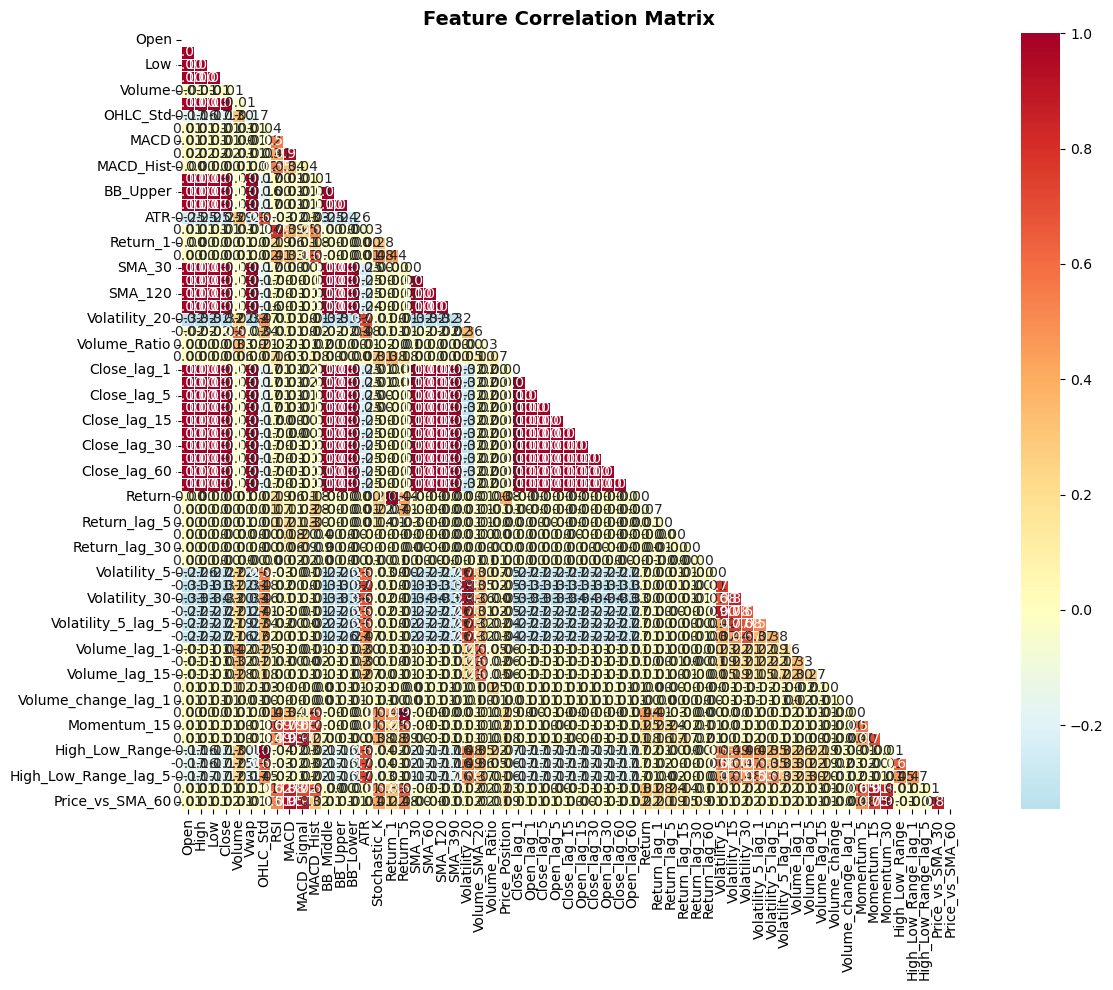

In [13]:
# =============================================================================
# CORRELATION HEATMAP
# =============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))
correlation_matrix = df.corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt='.2f', 
            cmap='RdYlBu_r', center=0, square=True, linewidths=0.5)
plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [31]:
# =============================================================================
# REMOVE HIGHLY CORRELATED FEATURES
# =============================================================================

def remove_highly_correlated(dataframe: pd.DataFrame, threshold: float = 0.65, protect_cols: list = None) -> pd.DataFrame:
    """Remove features that are highly correlated with each other
    
    Args:
        dataframe: Input DataFrame
        threshold: Correlation threshold above which to remove features
        protect_cols: List of columns to never drop (e.g., target variable)
    """
    if protect_cols is None:
        protect_cols = []
    
    corr_matrix = dataframe.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    
    # Find columns with correlation greater than threshold
    to_drop = set()
    for column in upper.columns:
        correlated = upper.index[upper[column] > threshold].tolist()
        if correlated:
            to_drop.update(correlated)
    
    # Remove protected columns from the drop list
    to_drop = to_drop - set(protect_cols)
    
    return dataframe.drop(columns=list(to_drop)), list(to_drop)

print("=" * 60)
print(f"REMOVING HIGHLY CORRELATED FEATURES (threshold = 0.65)")
print("=" * 60)

print(f"\nColumns BEFORE removal: {len(df.columns)}")
print(f"   {list(df.columns)}")

# Protect 'Close' from being dropped (it's our target variable)
df_reduced, dropped_cols = remove_highly_correlated(df, threshold=0.65, protect_cols=['Close'])

print(f"\n🗑️ Columns to remove (|r| > 0.65):")
for col in sorted(dropped_cols):
    print(f"   - {col}")

print(f"\n✅ Columns AFTER removal: {len(df_reduced.columns)}")
print(f"   {list(df_reduced.columns)}")

#df_reduced = df_reduced.drop(columns=['Open_lag_60'])
# Update df to the reduced version
df = df_reduced.copy()

print("\n" + "=" * 60)
print("UPDATED CORRELATION MATRIX (remaining features)")
print("=" * 60)
print(df.corr().round(2))

REMOVING HIGHLY CORRELATED FEATURES (threshold = 0.65)

Columns BEFORE removal: 25
   ['Close', 'Volume', 'Stochastic_K', 'Volume_SMA_20', 'Volume_Ratio', 'Price_Position', 'Return', 'Return_lag_1', 'Return_lag_5', 'Return_lag_15', 'Return_lag_30', 'Return_lag_60', 'Volatility_5_lag_1', 'Volatility_5_lag_5', 'Volatility_5_lag_15', 'Volume_lag_1', 'Volume_lag_5', 'Volume_lag_15', 'Volume_change', 'Volume_change_lag_1', 'Momentum_5', 'High_Low_Range', 'High_Low_Range_lag_1', 'High_Low_Range_lag_5', 'Price_vs_SMA_60']

🗑️ Columns to remove (|r| > 0.65):

✅ Columns AFTER removal: 25
   ['Close', 'Volume', 'Stochastic_K', 'Volume_SMA_20', 'Volume_Ratio', 'Price_Position', 'Return', 'Return_lag_1', 'Return_lag_5', 'Return_lag_15', 'Return_lag_30', 'Return_lag_60', 'Volatility_5_lag_1', 'Volatility_5_lag_5', 'Volatility_5_lag_15', 'Volume_lag_1', 'Volume_lag_5', 'Volume_lag_15', 'Volume_change', 'Volume_change_lag_1', 'Momentum_5', 'High_Low_Range', 'High_Low_Range_lag_1', 'High_Low_Range_lag

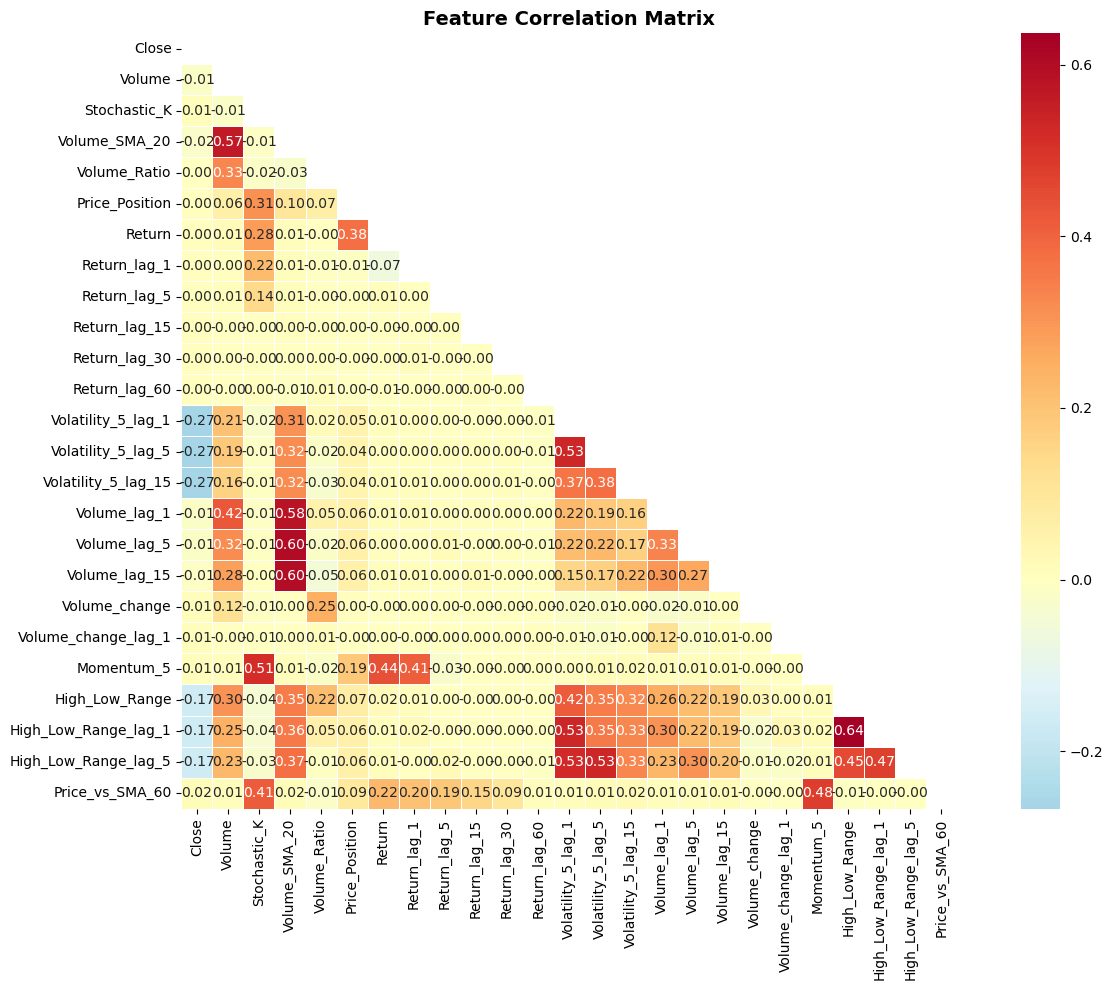

In [32]:
plt.figure(figsize=(14, 10))
correlation_matrix = df.corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt='.2f', 
            cmap='RdYlBu_r', center=0, square=True, linewidths=0.5)
plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [21]:
# =============================================================================
# PREPARE FINAL DATASET WITH TARGET VARIABLE
# =============================================================================

# IMPORTANT: We need to preserve 'Close' as our target before feature reduction
# Get the Close column from the original cleaned data before correlation removal
# We'll use df_reduced (features without highly correlated ones) + Close from before

# First, let's rebuild df_model with the reduced features PLUS the Close column
# The Close column should come from the data BEFORE the correlation removal step

# Check what we have available
print("=" * 60)
print("BUILDING FINAL MODELING DATASET")
print("=" * 60)

# df_reduced has the non-correlated features but may not have Close
# We need to get Close from before the dropna/cleaning step

# Re-read the original df data (this requires re-running earlier cells)
# For now, let's work with what we have in the kernel

# Check if Close exists in df or df_reduced
print(f"\n📋 Available DataFrames:")
print(f"   df columns: {list(df.columns)}")
print(f"   df shape: {df.shape}")
print(f"   df_reduced columns: {list(df_reduced.columns)}")
print(f"   df_reduced shape: {df_reduced.shape}")

# If Close is not in df, we have a problem - need to re-run from feature engineering
if 'Close' not in df.columns and 'Close' not in df_reduced.columns:
    print("\n⚠️ 'Close' column is missing!")
    print("   Please re-run cells from Feature Engineering (cell 8) onwards")
    print("   This will rebuild the data pipeline with Close preserved")
else:
    # Build the modeling dataframe
    if 'Close' in df_reduced.columns:
        df_model = df_reduced.copy()
    else:
        # Get Close from df and merge with df_reduced
        df_model = df_reduced.copy()
        df_model['Close'] = df['Close']
    
    print(f"\n✅ df_model created:")
    print(f"   Shape: {df_model.shape}")
    print(f"   Columns: {list(df_model.columns)}")

BUILDING FINAL MODELING DATASET

📋 Available DataFrames:
   df columns: ['Close', 'Volume', 'Stochastic_K', 'Volume_SMA_20', 'Volume_Ratio', 'Price_Position', 'Return', 'Return_lag_1', 'Return_lag_5', 'Return_lag_15', 'Return_lag_30', 'Return_lag_60', 'Volatility_5_lag_1', 'Volatility_5_lag_5', 'Volatility_5_lag_15', 'Volume_lag_1', 'Volume_lag_5', 'Volume_lag_15', 'Volume_change', 'Volume_change_lag_1', 'Momentum_5', 'High_Low_Range', 'High_Low_Range_lag_1', 'High_Low_Range_lag_5', 'Price_vs_SMA_60']
   df shape: (236469, 25)
   df_reduced columns: ['Close', 'Volume', 'Stochastic_K', 'Volume_SMA_20', 'Volume_Ratio', 'Price_Position', 'Return', 'Return_lag_1', 'Return_lag_5', 'Return_lag_15', 'Return_lag_30', 'Return_lag_60', 'Volatility_5_lag_1', 'Volatility_5_lag_5', 'Volatility_5_lag_15', 'Volume_lag_1', 'Volume_lag_5', 'Volume_lag_15', 'Volume_change', 'Volume_change_lag_1', 'Momentum_5', 'High_Low_Range', 'High_Low_Range_lag_1', 'High_Low_Range_lag_5', 'Price_vs_SMA_60']
   df_red

In [22]:
# Display final dataframe
df

,Close,Volume,Stochastic_K,Volume_SMA_20,Volume_Ratio,Price_Position,Return,Return_lag_1,Return_lag_5,Return_lag_15,...,Volume_lag_1,Volume_lag_5,Volume_lag_15,Volume_change,Volume_change_lag_1,Momentum_5,High_Low_Range,High_Low_Range_lag_1,High_Low_Range_lag_5,Price_vs_SMA_60
timestamp,,,,,,,,,,,,,,,,,,,,,
2025-02-05 17:17:00,602.7235,50805.000000,17.314815,58561.500000,0.867549,0.297222,0.000022,-0.000116,-0.000048,0.000149,...,49468.000000,79064.000000,84594.000000,0.027028,0.244760,-0.2065,0.1800,0.1700,0.1791,0.001264
2025-02-05 17:18:00,602.6500,40998.000000,5.454545,56133.350000,0.730368,0.230769,-0.000122,0.000022,0.000017,-0.000058,...,50805.000000,53367.000000,38143.000000,-0.193032,0.027028,-0.2900,0.1300,0.1800,0.0800,0.001082
2025-02-05 17:19:00,602.7500,29530.000000,23.636364,55610.200000,0.531018,0.619048,0.000166,-0.000122,-0.000066,-0.000017,...,40998.000000,36128.000000,57616.000000,-0.279721,-0.193032,-0.1500,0.2100,0.1300,0.0700,0.001184
2025-02-05 17:20:00,602.4300,89427.000000,0.000000,53657.200000,1.666636,0.000000,-0.000531,0.000166,-0.000199,-0.000050,...,29530.000000,39741.000000,40330.000000,2.028344,-0.279721,-0.3500,0.3000,0.2100,0.1700,0.000597
2025-02-05 17:21:00,602.4650,34305.000000,16.071429,52342.750000,0.655392,0.843750,0.000058,-0.000531,-0.000116,0.000025,...,89427.000000,49468.000000,40507.000000,-0.616391,2.028344,-0.2450,0.1600,0.3000,0.1700,0.000597
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-03-11 23:55:00,671.1400,1271.772116,91.538462,4140.699628,0.307139,0.800000,0.000134,-0.000088,0.000671,-0.000060,...,5824.536869,3823.326973,3391.193577,-0.781653,0.750881,0.1600,0.0500,0.1465,0.3600,-0.000523
2026-03-11 23:56:00,671.1900,2321.717331,94.707095,4132.650348,0.561799,0.223964,0.000075,0.000134,-0.000182,0.000089,...,1271.772116,2552.248861,2004.560568,0.825577,-0.781653,0.3320,0.0893,0.0500,0.2200,-0.000424
2026-03-11 23:57:00,670.9900,2667.295042,79.431757,4113.954974,0.648353,0.000000,-0.000298,0.000075,0.000286,0.000164,...,2321.717331,7629.308020,2225.137503,0.148846,0.825577,-0.0600,0.2000,0.0893,0.2700,-0.000689


# Training

In [16]:
from pytorch_forecasting import TemporalFusionTransformer, TimeSeriesDataSet
from pytorch_lightning import Trainer


c:\Users\batzi\anaconda3\envs\trading_brains\Lib\site-packages\pytorch_forecasting\models\base\_base_model.py:30: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


## Model Training

With limited data (87 rows), we'll use models that work well with small datasets:
1. **Ridge Regression** - baseline linear model with regularization
2. **Random Forest** - ensemble method, handles non-linearity
3. **XGBoost** - gradient boosting, often best for tabular data

We'll use walk-forward validation (time series split) to avoid data leakage.

In [23]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

print("=" * 60)
print("DATA PREPARATION FOR MODELING")
print("=" * 60)

# Use df_model which should have features + Close
if 'df_model' not in dir() or df_model.shape[0] == 0:
    print("⚠️ df_model not found or empty. Attempting to rebuild...")
    # Fallback: try to use df if it has Close
    if 'Close' in df.columns and df.shape[0] > 0:
        df_model = df.copy()
        print(f"   Using df with {len(df_model)} rows")
    else:
        print("❌ ERROR: No valid data available!")
        print("   Please re-run cells from Feature Engineering onwards")
        raise ValueError("No data available for modeling")

# Ensure no NaN values
nan_count = df_model.isnull().sum().sum()
print(f"\n🔍 NaN values in df_model: {nan_count}")

if nan_count > 0:
    print(f"   Dropping {df_model.isnull().any(axis=1).sum()} rows with NaN values...")
    df_model = df_model.dropna()
    print(f"   Remaining rows: {len(df_model)}")

# Check for infinite values in numeric columns only
numeric_cols = df_model.select_dtypes(include=[np.number]).columns
inf_mask = np.isinf(df_model[numeric_cols]).any(axis=1)
if inf_mask.sum() > 0:
    print(f"   Dropping {inf_mask.sum()} rows with infinite values...")
    df_model = df_model[~inf_mask]

# Define features and target
feature_columns = [col for col in df_model.columns if col != 'Close']
X = df_model[feature_columns].astype(np.float64).values
y = df_model['Close'].astype(np.float64).values

# Final check
print(f"\n✅ Data ready for modeling:")
print(f"   Features: {feature_columns}")
print(f"   X shape: {X.shape}")
print(f"   y shape: {y.shape}")

if X.shape[0] == 0:
    raise ValueError("No samples available for training! Please re-run from Feature Engineering.")

# Time Series Cross-Validation setup
n_splits = min(5, X.shape[0] // 10)  # Ensure we have enough samples per split
n_splits = max(2, n_splits)  # At least 2 splits
tscv = TimeSeriesSplit(n_splits=n_splits)

print(f"\n📊 Time Series Cross-Validation:")
print(f"   Number of splits: {n_splits}")

for i, (train_idx, test_idx) in enumerate(tscv.split(X)):
    print(f"   Split {i+1}: Train size={len(train_idx)}, Test size={len(test_idx)}")

DATA PREPARATION FOR MODELING

🔍 NaN values in df_model: 0

✅ Data ready for modeling:
   Features: ['Volume', 'Stochastic_K', 'Volume_SMA_20', 'Volume_Ratio', 'Price_Position', 'Return', 'Return_lag_1', 'Return_lag_5', 'Return_lag_15', 'Return_lag_30', 'Return_lag_60', 'Volatility_5_lag_1', 'Volatility_5_lag_5', 'Volatility_5_lag_15', 'Volume_lag_1', 'Volume_lag_5', 'Volume_lag_15', 'Volume_change', 'Volume_change_lag_1', 'Momentum_5', 'High_Low_Range', 'High_Low_Range_lag_1', 'High_Low_Range_lag_5', 'Price_vs_SMA_60']
   X shape: (236469, 24)
   y shape: (236469,)

📊 Time Series Cross-Validation:
   Number of splits: 5
   Split 1: Train size=39414, Test size=39411
   Split 2: Train size=78825, Test size=39411
   Split 3: Train size=118236, Test size=39411
   Split 4: Train size=157647, Test size=39411
   Split 5: Train size=197058, Test size=39411


In [24]:
# =============================================================================
# MODEL TRAINING WITH TIME SERIES CROSS-VALIDATION
# =============================================================================
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Try to import XGBoost, fall back to GradientBoosting if not available
try:
    from xgboost import XGBRegressor
    use_xgboost = True
except ImportError:
    print("⚠️ XGBoost not installed, using sklearn's GradientBoostingRegressor instead")
    use_xgboost = False

# Define models to compare
if use_xgboost:
    models = {
        'Ridge Regression': Ridge(alpha=1.0),
        'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
        'XGBoost': XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, verbosity=0)
    }
else:
    models = {
        'Ridge Regression': Ridge(alpha=1.0),
        'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
        'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42)
    }

# Store results
results = {name: {'rmse': [], 'mae': [], 'r2': []} for name in models.keys()}

print("=" * 60)
print("MODEL TRAINING WITH TIME SERIES CROSS-VALIDATION")
print("=" * 60)

# Scaler for features
scaler = StandardScaler()

for name, model in models.items():
    print(f"\n🔄 Training: {name}")
    
    for train_idx, test_idx in tscv.split(X):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        
        # Scale features
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)
        
        # Train model
        model.fit(X_train_scaled, y_train)
        
        # Predict
        y_pred = model.predict(X_test_scaled)
        
        # Calculate metrics
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        mae = mean_absolute_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        
        results[name]['rmse'].append(rmse)
        results[name]['mae'].append(mae)
        results[name]['r2'].append(r2)
    
    avg_rmse = np.mean(results[name]['rmse'])
    avg_mae = np.mean(results[name]['mae'])
    avg_r2 = np.mean(results[name]['r2'])
    
    print(f"   Avg RMSE: ${avg_rmse:.4f}")
    print(f"   Avg MAE:  ${avg_mae:.4f}")
    print(f"   Avg R²:   {avg_r2:.4f}")

# Summary comparison
print("\n" + "=" * 60)
print("MODEL COMPARISON SUMMARY")
print("=" * 60)

summary_data = []
for name in models.keys():
    summary_data.append({
        'Model': name,
        'Avg RMSE': np.mean(results[name]['rmse']),
        'Std RMSE': np.std(results[name]['rmse']),
        'Avg MAE': np.mean(results[name]['mae']),
        'Avg R²': np.mean(results[name]['r2'])
    })

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

# Best model
best_model_name = summary_df.loc[summary_df['Avg RMSE'].idxmin(), 'Model']
print(f"\n🏆 Best Model: {best_model_name}")

MODEL TRAINING WITH TIME SERIES CROSS-VALIDATION

🔄 Training: Ridge Regression
   Avg RMSE: $54.7552
   Avg MAE:  $52.8922
   Avg R²:   -39.2693

🔄 Training: Random Forest
   Avg RMSE: $50.3137
   Avg MAE:  $47.2637
   Avg R²:   -34.2715

🔄 Training: XGBoost
   Avg RMSE: $45.6558
   Avg MAE:  $41.6275
   Avg R²:   -26.7775

MODEL COMPARISON SUMMARY
           Model  Avg RMSE  Std RMSE   Avg MAE     Avg R²
Ridge Regression 54.755242 16.887770 52.892241 -39.269326
   Random Forest 50.313703 15.886935 47.263653 -34.271549
         XGBoost 45.655797 14.225332 41.627517 -26.777540

🏆 Best Model: XGBoost


FINAL MODEL EVALUATION (XGBoost)

📊 Holdout Set Performance (last 1440 minutes):
   RMSE: $41.9670
   MAE:  $36.1609
   R²:   -295.1619


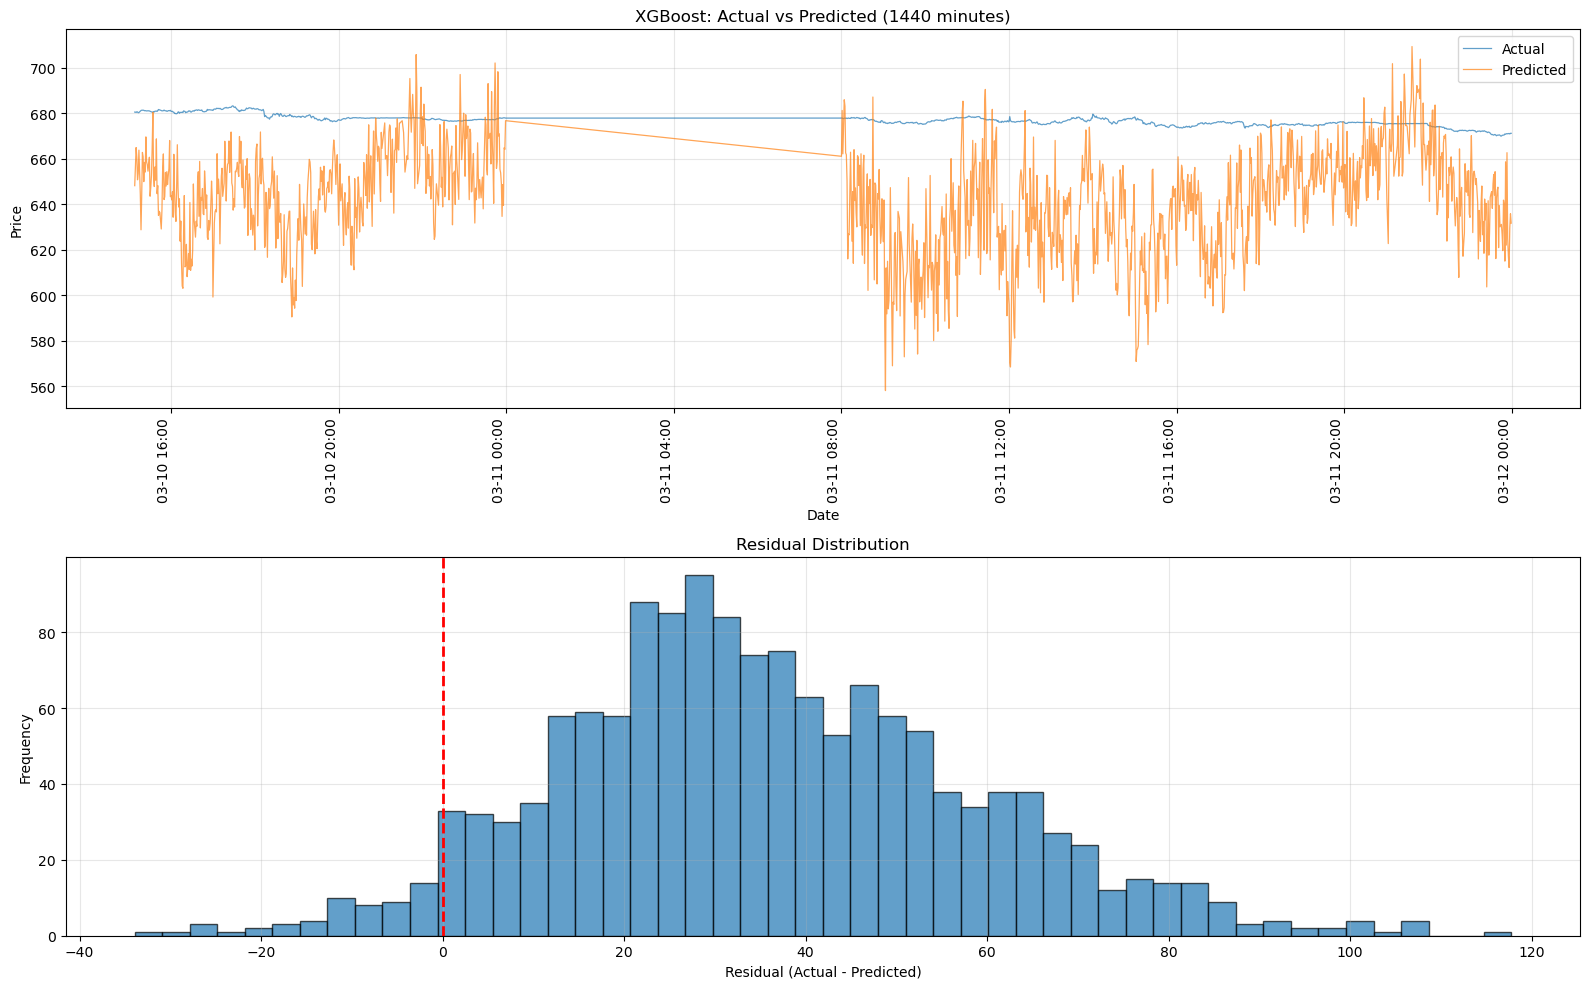


📊 Feature Importance:
             Feature  Importance
 Volatility_5_lag_15    0.107487
  Volatility_5_lag_1    0.100086
  Volatility_5_lag_5    0.091321
       Return_lag_15    0.072504
       Return_lag_30    0.071881
       Return_lag_60    0.069126
       Volume_SMA_20    0.057785
        Return_lag_1    0.053272
              Return    0.049508
        Return_lag_5    0.049279
        Volume_lag_5    0.033557
        Volume_lag_1    0.029981
High_Low_Range_lag_5    0.028068
              Volume    0.026890
     Price_vs_SMA_60    0.026157
       Volume_lag_15    0.025887
High_Low_Range_lag_1    0.024171
      High_Low_Range    0.023849
      Price_Position    0.015153
 Volume_change_lag_1    0.011091
       Volume_change    0.010811
        Volume_Ratio    0.009929
          Momentum_5    0.006767
        Stochastic_K    0.005440


In [25]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

holdout_size = 1440

X_train_final = X[:-holdout_size]
X_test_final = X[-holdout_size:]
y_train_final = y[:-holdout_size]
y_test_final = y[-holdout_size:]

# Get the dates for the test set
test_dates = df_model.index[-holdout_size:]

# Scale
X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled = scaler.transform(X_test_final)

# Train best model (based on results)
if best_model_name == 'Ridge Regression':
    best_model = Ridge(alpha=1.0)
elif best_model_name == 'Random Forest':
    best_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
elif best_model_name == 'XGBoost' and use_xgboost:
    from xgboost import XGBRegressor
    best_model = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, verbosity=0)
else:
    best_model = GradientBoostingRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42)

best_model.fit(X_train_scaled, y_train_final)
y_pred_final = best_model.predict(X_test_scaled)

results_df = pd.DataFrame({
    'timestamp': test_dates,
    'actual': y_test_final.values if hasattr(y_test_final, 'values') else y_test_final,
    'predicted': y_pred_final
})

# Final metrics
final_rmse = np.sqrt(mean_squared_error(y_test_final, y_pred_final))
final_mae = mean_absolute_error(y_test_final, y_pred_final)
final_r2 = r2_score(y_test_final, y_pred_final)

print("=" * 60)
print(f"FINAL MODEL EVALUATION ({best_model_name})")
print("=" * 60)
print(f"\n📊 Holdout Set Performance (last {holdout_size} minutes):")
print(f"   RMSE: ${final_rmse:.4f}")
print(f"   MAE:  ${final_mae:.4f}")
print(f"   R²:   {final_r2:.4f}")

# Visualization - stacked vertically for better readability with large holdout
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Plot 1: Actual vs Predicted with dates on x-axis
axes[0].plot(test_dates, y_test_final, label='Actual', alpha=0.7, linewidth=0.9)
axes[0].plot(test_dates, y_pred_final, label='Predicted', alpha=0.7, linewidth=0.9)
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Price')
axes[0].set_title(f'{best_model_name}: Actual vs Predicted ({holdout_size} minutes)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Format x-axis dates
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
axes[0].xaxis.set_major_locator(mdates.AutoDateLocator())
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=90, ha='right')

# Plot 2: Residuals
residuals = y_test_final - y_pred_final
axes[1].hist(residuals, bins=50, edgecolor='black', alpha=0.7)
axes[1].axvline(x=0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel('Residual (Actual - Predicted)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Residual Distribution')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Feature importance (if available)
if hasattr(best_model, 'feature_importances_'):
    print("\n📊 Feature Importance:")
    importance_df = pd.DataFrame({
        'Feature': feature_columns,
        'Importance': best_model.feature_importances_
    }).sort_values('Importance', ascending=False)
    print(importance_df.to_string(index=False))
elif hasattr(best_model, 'coef_'):
    print("\n📊 Feature Coefficients (Ridge):")
    coef_df = pd.DataFrame({
        'Feature': feature_columns,
        'Coefficient': best_model.coef_
    }).sort_values('Coefficient', key=abs, ascending=False)
    print(coef_df.to_string(index=False))

In [26]:
results_df

,timestamp,actual,predicted
0,2026-03-10 15:08:00,680.6000,648.225952
1,2026-03-10 15:09:00,680.5900,656.572449
2,2026-03-10 15:10:00,680.4405,664.987061
3,2026-03-10 15:11:00,680.7400,660.618347
4,2026-03-10 15:12:00,680.6400,650.805054
...,...,...,...
1435,2026-03-11 23:55:00,671.1400,617.420227
1436,2026-03-11 23:56:00,671.1900,612.205933
1437,2026-03-11 23:57:00,670.9900,629.580933
1438,2026-03-11 23:58:00,671.2548,635.868164


In [25]:
results_df.to_csv(r'C:\Users\batzi\OneDrive\Dokumente\trading_brains\test_actual_vs_predicted.csv', index=False)

# Multi-Horizon Price Prediction

Extending our model to predict closing prices for larger timeframes (5, 15, 30, 60 minutes ahead).

In [28]:
# =============================================================================
# 1. MODIFY TARGET VARIABLE - Multi-Horizon Targets
# =============================================================================

def create_multi_horizon_targets(data, horizons=[5, 15, 30, 60]):
    """
    Create target variables for multiple prediction horizons.
    
    Parameters:
    -----------
    data : DataFrame
        DataFrame with 'close' column (OHLCV data)
    horizons : list
        List of prediction horizons in minutes
        
    Returns:
    --------
    DataFrame with additional target columns
    """
    df_targets = data.copy()
    
    for h in horizons:
        # Absolute price target
        df_targets[f'target_close_{h}min'] = df_targets['Close'].shift(-h)
        
        # Return-based target (often better for ML)
        df_targets[f'target_return_{h}min'] = (
            df_targets['Close'].shift(-h) - df_targets['Close']
        ) / df_targets['Close'] * 100  # Percentage return
        
        # Direction target (for classification)
        df_targets[f'target_direction_{h}min'] = (
            df_targets['Close'].shift(-h) > df_targets['Close']
        ).astype(int)
    
    return df_targets

# Apply to our data
df_multi_horizon = create_multi_horizon_targets(df)

# Display the new target columns
target_cols = [col for col in df_multi_horizon.columns if 'target_' in col]
print(f"Created {len(target_cols)} new target columns:")
print(target_cols)
print(f"\nSample of multi-horizon targets:")
df_multi_horizon[['Close'] + target_cols[:8]].tail(10)

Created 12 new target columns:
['target_close_5min', 'target_return_5min', 'target_direction_5min', 'target_close_15min', 'target_return_15min', 'target_direction_15min', 'target_close_30min', 'target_return_30min', 'target_direction_30min', 'target_close_60min', 'target_return_60min', 'target_direction_60min']

Sample of multi-horizon targets:


,Close,target_close_5min,target_return_5min,target_direction_5min,target_close_15min,target_return_15min,target_direction_15min,target_close_30min,target_return_30min
timestamp,,,,,,,,,
2026-03-11 23:50:00,670.9800,671.1400,0.023846,1,NaN,NaN,0,NaN,NaN
2026-03-11 23:51:00,670.8580,671.1900,0.049489,1,NaN,NaN,0,NaN,NaN
2026-03-11 23:52:00,671.0500,670.9900,-0.008941,0,NaN,NaN,0,NaN,NaN
2026-03-11 23:53:00,671.1090,671.2548,0.021725,1,NaN,NaN,0,NaN,NaN
2026-03-11 23:54:00,671.0500,671.2500,0.029804,1,NaN,NaN,0,NaN,NaN
2026-03-11 23:55:00,671.1400,NaN,NaN,0,NaN,NaN,0,NaN,NaN
2026-03-11 23:56:00,671.1900,NaN,NaN,0,NaN,NaN,0,NaN,NaN
2026-03-11 23:57:00,670.9900,NaN,NaN,0,NaN,NaN,0,NaN,NaN
2026-03-11 23:58:00,671.2548,NaN,NaN,0,NaN,NaN,0,NaN,NaN


In [30]:
# =============================================================================
# 2. AGGREGATE FEATURES FROM MULTIPLE TIMEFRAMES
# =============================================================================

def create_multiscale_features(data, windows=[5, 15, 30, 60, 120]):
    """
    Create features at multiple time scales for longer-horizon predictions.
    
    Parameters:
    -----------
    data : DataFrame
        OHLCV DataFrame
    windows : list
        List of rolling window sizes in minutes
        
    Returns:
    --------
    DataFrame with multi-scale features
    """
    df_features = data.copy()
    
    for window in windows:
        # Price-based features
        df_features[f'sma_{window}'] = df_features['Close'].rolling(window).mean()
        df_features[f'ema_{window}'] = df_features['Close'].ewm(span=window).mean()
        df_features[f'std_{window}'] = df_features['Close'].rolling(window).std()
        
        # Price relative to moving average
        df_features[f'close_vs_sma_{window}'] = (
            df_features['Close'] / df_features[f'sma_{window}'] - 1
        ) * 100
        
        # Momentum / Returns over window
        df_features[f'return_{window}'] = df_features['Close'].pct_change(window) * 100
        
        # Volatility features
        df_features[f'high_low_range_{window}'] = (
            df_features['High'].rolling(window).max() - 
            df_features['Low'].rolling(window).min()
        )
        df_features[f'atr_{window}'] = (
            df_features['High'].rolling(window).max() - 
            df_features['Low'].rolling(window).min()
        ) / df_features['Close'] * 100  # Normalized ATR
        
        # Volume features
        df_features[f'volume_ma_{window}'] = df_features['Volume'].rolling(window).mean()
        df_features[f'volume_ratio_{window}'] = (
            df_features['Volume'] / df_features[f'volume_ma_{window}']
        )
        
        # RSI approximation
        delta = df_features['Close'].diff()
        gain = delta.where(delta > 0, 0).rolling(window).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window).mean()
        rs = gain / (loss + 1e-10)
        df_features[f'rsi_{window}'] = 100 - (100 / (1 + rs))
        
        # Bollinger Band position
        upper_band = df_features[f'sma_{window}'] + 2 * df_features[f'std_{window}']
        lower_band = df_features[f'sma_{window}'] - 2 * df_features[f'std_{window}']
        df_features[f'bb_position_{window}'] = (
            (df_features['Close'] - lower_band) / (upper_band - lower_band + 1e-10)
        )
    
    return df_features

# Apply multi-scale features
df_multiscale = create_multiscale_features(df_multi_horizon)

# Show new feature count
new_feature_cols = [col for col in df_multiscale.columns 
                    if any(str(w) in col for w in [5, 15, 30, 60, 120])
                    and 'target_' not in col]
print(f"Created {len(new_feature_cols)} multi-scale features")
print(f"\nFeature groups per window:")
for window in [5, 15, 30, 60, 120]:
    cols = [col for col in new_feature_cols if f'_{window}' in col]
    print(f"  {window}-min window: {len(cols)} features")

print(f"\nDataFrame shape: {df_multiscale.shape}")

KeyError: 'High'

In [ ]:
# =============================================================================
# 3. RESAMPLE OHLCV TO LARGER TIMEFRAMES
# =============================================================================

def resample_ohlcv(data, timeframe='60T'):
    """
    Resample minute OHLCV data to larger timeframes.
    
    Parameters:
    -----------
    data : DataFrame
        OHLCV DataFrame with DatetimeIndex
    timeframe : str
        Target timeframe (e.g., '5T', '15T', '30T', '60T', '1D')
        
    Returns:
    --------
    Resampled OHLCV DataFrame
    """
    # Ensure datetime index
    df_resample = data.copy()
    if not isinstance(df_resample.index, pd.DatetimeIndex):
        if 'timestamp' in df_resample.columns:
            df_resample.set_index('timestamp', inplace=True)
        elif 'date' in df_resample.columns:
            df_resample.set_index('date', inplace=True)
    
    # Standard OHLCV aggregation rules
    ohlcv_dict = {
        'open': 'first',
        'high': 'max',
        'low': 'min',
        'close': 'last',
        'volume': 'sum'
    }
    
    # Only aggregate columns that exist
    agg_dict = {k: v for k, v in ohlcv_dict.items() if k in df_resample.columns}
    
    resampled = df_resample.resample(timeframe).agg(agg_dict).dropna()
    
    return resampled

# Create different timeframe datasets
print("Resampling to different timeframes...\n")

timeframes = {
    '5T': '5-minute bars',
    '15T': '15-minute bars', 
    '30T': '30-minute bars',
    '60T': '60-minute (hourly) bars',
    '1D': 'Daily bars'
}

resampled_data = {}
for tf, desc in timeframes.items():
    resampled_data[tf] = resample_ohlcv(df, tf)
    print(f"{desc}: {len(resampled_data[tf])} bars")

# Show sample of hourly data
print("\n--- Sample of Hourly (60T) Resampled Data ---")
resampled_data['60T'].tail(10)

## Multi-Output Model

Train a single model that predicts multiple horizons simultaneously. This can capture relationships between different forecast horizons.

In [ ]:
# =============================================================================
# 4. MULTI-OUTPUT MODEL - Predict Multiple Horizons Simultaneously
# =============================================================================

from sklearn.multioutput import MultiOutputRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import numpy as np

def prepare_multi_output_data(data, horizons=[5, 15, 30, 60]):
    """
    Prepare data for multi-output regression.
    """
    df_prep = data.copy()
    
    # Define target columns (using returns for better scaling)
    target_cols = [f'target_return_{h}min' for h in horizons]
    
    # Check which target columns exist
    available_targets = [col for col in target_cols if col in df_prep.columns]
    
    if not available_targets:
        raise ValueError("No target columns found. Run create_multi_horizon_targets first.")
    
    # Define feature columns (exclude targets and raw OHLCV)
    exclude_patterns = ['target_', 'open', 'high', 'low', 'close', 'volume']
    feature_cols = [col for col in df_prep.columns 
                    if not any(pattern in col for pattern in exclude_patterns)]
    
    # If no features found, use all numeric columns except targets
    if not feature_cols:
        feature_cols = [col for col in df_prep.select_dtypes(include=[np.number]).columns
                       if 'target_' not in col]
    
    # Drop NaN rows
    df_clean = df_prep.dropna(subset=available_targets + feature_cols)
    
    X = df_clean[feature_cols].values
    y = df_clean[available_targets].values
    
    return X, y, feature_cols, available_targets

# Prepare data
print("Preparing multi-output data...")
X_multi, y_multi, feature_names, target_names = prepare_multi_output_data(df_multiscale)

print(f"Features: {len(feature_names)}")
print(f"Targets: {target_names}")
print(f"Samples: {len(X_multi)}")

# Train/test split (time-based)
split_idx = int(len(X_multi) * 0.8)
X_train_mo, X_test_mo = X_multi[:split_idx], X_multi[split_idx:]
y_train_mo, y_test_mo = y_multi[:split_idx], y_multi[split_idx:]

print(f"\nTrain samples: {len(X_train_mo)}")
print(f"Test samples: {len(X_test_mo)}")

In [ ]:
# Train Multi-Output Model
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Scale features
scaler_mo = StandardScaler()
X_train_mo_scaled = scaler_mo.fit_transform(X_train_mo)
X_test_mo_scaled = scaler_mo.transform(X_test_mo)

# Train multi-output model
print("Training Multi-Output GradientBoosting model...")
print("(This may take a few minutes)\n")

multi_model = MultiOutputRegressor(
    GradientBoostingRegressor(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        random_state=42
    ),
    n_jobs=-1  # Parallelize across outputs
)

multi_model.fit(X_train_mo_scaled, y_train_mo)

# Predictions
y_pred_mo = multi_model.predict(X_test_mo_scaled)

# Evaluate each horizon
print("=" * 60)
print("Multi-Output Model Results by Horizon")
print("=" * 60)

results_mo = {}
for i, target in enumerate(target_names):
    horizon = target.replace('target_return_', '').replace('min', '')
    rmse = np.sqrt(mean_squared_error(y_test_mo[:, i], y_pred_mo[:, i]))
    mae = mean_absolute_error(y_test_mo[:, i], y_pred_mo[:, i])
    r2 = r2_score(y_test_mo[:, i], y_pred_mo[:, i])
    
    # Directional accuracy
    actual_direction = (y_test_mo[:, i] > 0).astype(int)
    pred_direction = (y_pred_mo[:, i] > 0).astype(int)
    dir_accuracy = (actual_direction == pred_direction).mean() * 100
    
    results_mo[horizon] = {
        'RMSE': rmse,
        'MAE': mae,
        'R2': r2,
        'Direction_Accuracy': dir_accuracy
    }
    
    print(f"\n{horizon}-minute Horizon:")
    print(f"  RMSE: {rmse:.4f}%")
    print(f"  MAE:  {mae:.4f}%")
    print(f"  R²:   {r2:.4f}")
    print(f"  Directional Accuracy: {dir_accuracy:.1f}%")

# Summary DataFrame
results_mo_df = pd.DataFrame(results_mo).T
results_mo_df.index.name = 'Horizon (min)'
print("\n" + "=" * 60)
print("Summary Table:")
results_mo_df

In [ ]:
# Visualize Multi-Output Model Performance
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

horizons_list = list(results_mo.keys())

# Plot 1: RMSE by horizon
ax1 = axes[0, 0]
rmse_values = [results_mo[h]['RMSE'] for h in horizons_list]
ax1.bar(horizons_list, rmse_values, color='steelblue', alpha=0.8)
ax1.set_xlabel('Forecast Horizon (minutes)')
ax1.set_ylabel('RMSE (%)')
ax1.set_title('RMSE by Forecast Horizon')
ax1.grid(axis='y', alpha=0.3)

# Plot 2: R² by horizon
ax2 = axes[0, 1]
r2_values = [results_mo[h]['R2'] for h in horizons_list]
colors = ['green' if r > 0 else 'red' for r in r2_values]
ax2.bar(horizons_list, r2_values, color=colors, alpha=0.8)
ax2.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax2.set_xlabel('Forecast Horizon (minutes)')
ax2.set_ylabel('R² Score')
ax2.set_title('R² Score by Forecast Horizon')
ax2.grid(axis='y', alpha=0.3)

# Plot 3: Directional Accuracy by horizon
ax3 = axes[1, 0]
dir_values = [results_mo[h]['Direction_Accuracy'] for h in horizons_list]
ax3.bar(horizons_list, dir_values, color='orange', alpha=0.8)
ax3.axhline(y=50, color='red', linestyle='--', linewidth=1, label='Random (50%)')
ax3.set_xlabel('Forecast Horizon (minutes)')
ax3.set_ylabel('Accuracy (%)')
ax3.set_title('Directional Accuracy by Horizon')
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

# Plot 4: Actual vs Predicted for 60-min horizon
ax4 = axes[1, 1]
idx_60 = target_names.index('target_return_60min') if 'target_return_60min' in target_names else -1
if idx_60 >= 0:
    sample_size = min(200, len(y_test_mo))
    ax4.plot(y_test_mo[:sample_size, idx_60], label='Actual', alpha=0.7)
    ax4.plot(y_pred_mo[:sample_size, idx_60], label='Predicted', alpha=0.7)
    ax4.set_xlabel('Sample')
    ax4.set_ylabel('Return (%)')
    ax4.set_title('60-min Return: Actual vs Predicted')
    ax4.legend()
    ax4.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Sequence Models (LSTM) for Long-Horizon Prediction

LSTM networks can capture temporal dependencies in sequential data, making them well-suited for longer forecast horizons where patterns over time matter.

In [ ]:
# =============================================================================
# 5. SEQUENCE MODEL (LSTM) FOR LONGER HORIZONS
# =============================================================================

# Check if TensorFlow is available
try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
    from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
    from tensorflow.keras.optimizers import Adam
    TF_AVAILABLE = True
    print(f"TensorFlow version: {tf.__version__}")
except ImportError:
    TF_AVAILABLE = False
    print("TensorFlow not installed. Install with: pip install tensorflow")
    print("Skipping LSTM model...")

In [ ]:
# Prepare sequence data for LSTM
def create_sequences(data, sequence_length=60, forecast_horizon=60):
    """
    Create sequences for LSTM input.
    
    Parameters:
    -----------
    data : DataFrame
        Input DataFrame with features
    sequence_length : int
        Number of time steps to look back
    forecast_horizon : int
        How many steps ahead to predict
        
    Returns:
    --------
    X : array of shape (samples, sequence_length, features)
    y : array of target values
    """
    # Select numeric features
    feature_cols = data.select_dtypes(include=[np.number]).columns.tolist()
    
    # Remove target columns from features
    feature_cols = [c for c in feature_cols if 'target_' not in c]
    
    # Target column
    target_col = f'target_return_{forecast_horizon}min'
    if target_col not in data.columns:
        # Fall back to computing it
        data = data.copy()
        data[target_col] = (data['close'].shift(-forecast_horizon) - data['close']) / data['close'] * 100
    
    # Drop NaN
    df_clean = data.dropna()
    
    # Extract values
    features = df_clean[feature_cols].values
    target = df_clean[target_col].values
    
    # Normalize features
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features)
    
    X, y = [], []
    for i in range(sequence_length, len(features_scaled) - forecast_horizon):
        X.append(features_scaled[i-sequence_length:i])
        y.append(target[i])
    
    return np.array(X), np.array(y), scaler, feature_cols

# Only run if TensorFlow is available
if TF_AVAILABLE:
    print("Creating sequences for LSTM...")
    SEQUENCE_LENGTH = 60  # Look back 60 minutes
    FORECAST_HORIZON = 60  # Predict 60 minutes ahead
    
    X_seq, y_seq, seq_scaler, seq_features = create_sequences(
        df_multiscale, 
        sequence_length=SEQUENCE_LENGTH,
        forecast_horizon=FORECAST_HORIZON
    )
    
    print(f"Sequence shape: {X_seq.shape}")
    print(f"Target shape: {y_seq.shape}")
    print(f"Features per timestep: {len(seq_features)}")
    
    # Time-based train/test split
    split_idx = int(len(X_seq) * 0.8)
    X_train_seq, X_test_seq = X_seq[:split_idx], X_seq[split_idx:]
    y_train_seq, y_test_seq = y_seq[:split_idx], y_seq[split_idx:]
    
    print(f"\nTrain sequences: {len(X_train_seq)}")
    print(f"Test sequences: {len(X_test_seq)}")

In [ ]:
# Build and Train LSTM Model
if TF_AVAILABLE:
    def build_lstm_model(sequence_length, n_features, forecast_horizon=1):
        """
        Build LSTM model for time series forecasting.
        """
        model = Sequential([
            # First LSTM layer
            LSTM(128, return_sequences=True, 
                 input_shape=(sequence_length, n_features)),
            BatchNormalization(),
            Dropout(0.2),
            
            # Second LSTM layer
            LSTM(64, return_sequences=True),
            BatchNormalization(),
            Dropout(0.2),
            
            # Third LSTM layer
            LSTM(32, return_sequences=False),
            BatchNormalization(),
            Dropout(0.2),
            
            # Dense layers
            Dense(32, activation='relu'),
            Dropout(0.1),
            Dense(16, activation='relu'),
            
            # Output layer
            Dense(1)  # Single output for point prediction
        ])
        
        model.compile(
            optimizer=Adam(learning_rate=0.001),
            loss='mse',
            metrics=['mae']
        )
        
        return model
    
    # Build model
    n_features = X_train_seq.shape[2]
    lstm_model = build_lstm_model(SEQUENCE_LENGTH, n_features, FORECAST_HORIZON)
    
    print("LSTM Model Architecture:")
    lstm_model.summary()

In [ ]:
# Train LSTM Model
if TF_AVAILABLE:
    print("Training LSTM model...")
    print("=" * 60)
    
    # Callbacks
    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
    
    reduce_lr = ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
    
    # Train
    history = lstm_model.fit(
        X_train_seq, y_train_seq,
        validation_split=0.15,
        epochs=50,
        batch_size=64,
        callbacks=[early_stopping, reduce_lr],
        verbose=1
    )
    
    print("\nTraining complete!")

In [ ]:
# Evaluate LSTM Model
if TF_AVAILABLE:
    # Predictions
    y_pred_lstm = lstm_model.predict(X_test_seq).flatten()
    
    # Metrics
    lstm_rmse = np.sqrt(mean_squared_error(y_test_seq, y_pred_lstm))
    lstm_mae = mean_absolute_error(y_test_seq, y_pred_lstm)
    lstm_r2 = r2_score(y_test_seq, y_pred_lstm)
    
    # Directional accuracy
    actual_dir = (y_test_seq > 0).astype(int)
    pred_dir = (y_pred_lstm > 0).astype(int)
    lstm_dir_acc = (actual_dir == pred_dir).mean() * 100
    
    print("=" * 60)
    print(f"LSTM Model Results ({FORECAST_HORIZON}-minute Horizon)")
    print("=" * 60)
    print(f"RMSE: {lstm_rmse:.4f}%")
    print(f"MAE:  {lstm_mae:.4f}%")
    print(f"R²:   {lstm_r2:.4f}")
    print(f"Directional Accuracy: {lstm_dir_acc:.1f}%")
    
    # Compare with Multi-Output model
    if '60' in results_mo:
        print("\n" + "-" * 60)
        print("Comparison with Multi-Output GBM (60-min horizon):")
        print("-" * 60)
        print(f"{'Metric':<25} {'LSTM':<15} {'Multi-Output GBM':<15}")
        print("-" * 60)
        print(f"{'RMSE':<25} {lstm_rmse:<15.4f} {results_mo['60']['RMSE']:<15.4f}")
        print(f"{'MAE':<25} {lstm_mae:<15.4f} {results_mo['60']['MAE']:<15.4f}")
        print(f"{'R²':<25} {lstm_r2:<15.4f} {results_mo['60']['R2']:<15.4f}")
        print(f"{'Direction Acc.':<25} {lstm_dir_acc:<15.1f} {results_mo['60']['Direction_Accuracy']:<15.1f}")

In [ ]:
# Visualize LSTM Results
if TF_AVAILABLE:
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Plot 1: Training history - Loss
    ax1 = axes[0, 0]
    ax1.plot(history.history['loss'], label='Training Loss')
    ax1.plot(history.history['val_loss'], label='Validation Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('MSE Loss')
    ax1.set_title('LSTM Training History - Loss')
    ax1.legend()
    ax1.grid(alpha=0.3)
    
    # Plot 2: Training history - MAE
    ax2 = axes[0, 1]
    ax2.plot(history.history['mae'], label='Training MAE')
    ax2.plot(history.history['val_mae'], label='Validation MAE')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('MAE')
    ax2.set_title('LSTM Training History - MAE')
    ax2.legend()
    ax2.grid(alpha=0.3)
    
    # Plot 3: Actual vs Predicted
    ax3 = axes[1, 0]
    sample_size = min(300, len(y_test_seq))
    ax3.plot(y_test_seq[:sample_size], label='Actual', alpha=0.7)
    ax3.plot(y_pred_lstm[:sample_size], label='Predicted', alpha=0.7)
    ax3.set_xlabel('Sample')
    ax3.set_ylabel('Return (%)')
    ax3.set_title(f'{FORECAST_HORIZON}-min Return: Actual vs Predicted (LSTM)')
    ax3.legend()
    ax3.grid(alpha=0.3)
    
    # Plot 4: Scatter plot Actual vs Predicted
    ax4 = axes[1, 1]
    ax4.scatter(y_test_seq, y_pred_lstm, alpha=0.3, s=10)
    ax4.plot([y_test_seq.min(), y_test_seq.max()], 
             [y_test_seq.min(), y_test_seq.max()], 
             'r--', linewidth=2, label='Perfect Prediction')
    ax4.set_xlabel('Actual Return (%)')
    ax4.set_ylabel('Predicted Return (%)')
    ax4.set_title('LSTM: Actual vs Predicted Scatter')
    ax4.legend()
    ax4.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()

## Summary: Multi-Horizon Price Prediction

| Approach | Best For | Key Points |
|----------|----------|------------|
| **Multi-Horizon Targets** | Quick experimentation | Simple shift of target variable |
| **Multi-Scale Features** | Capturing patterns at different frequencies | Rolling windows at 5, 15, 30, 60, 120 min |
| **OHLCV Resampling** | Training on aggregated data directly | Reduces noise, but also data points |
| **Multi-Output Model** | Predicting multiple horizons at once | Can share learned representations |
| **LSTM Sequence Model** | Capturing temporal patterns | Better for longer sequences, more compute |

### Next Steps
- Tune hyperparameters for best performing model
- Try attention mechanisms (Transformer) for very long horizons
- Combine features from multiple resampled timeframes
- Add exogenous features (sentiment, macro indicators)